# Day 6 — First Machine Learning Model

## Goal
Train a logistic regression model to predict AAPL's next-trading-day
direction using historical market features.

## Topics
- Supervised machine learning
- Features (X) and target (y)
- Logistic regression
- Feature scaling
- Training with fit()
- Predicting with predict() and predict_proba()
- Classification metrics
- Confusion matrix
- Comparing against baseline models
- Model coefficients
- Data leakage

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv(
    "../data/raw/AAPL_daily_raw.csv",
    index_col="Date",
    parse_dates=True)

data = data.sort_index()

print("Dataset shape:", data.shape)

data.head()

Dataset shape: (2766, 9)


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,daily_return
Date,,,,,,,,,
2015-01-02 00:00:00-05:00,27.847500,27.860001,26.837500,27.332500,24.171755,212818400,0.0,0.0,NaN
2015-01-05 00:00:00-05:00,27.072500,27.162500,26.352501,26.562500,23.490799,257142000,0.0,0.0,-0.028172
2015-01-06 00:00:00-05:00,26.635000,26.857500,26.157499,26.565001,23.493013,263188400,0.0,0.0,0.000094
2015-01-07 00:00:00-05:00,26.799999,27.049999,26.674999,26.937500,23.822430,160423600,0.0,0.0,0.014022
2015-01-08 00:00:00-05:00,27.307501,28.037500,27.174999,27.972500,24.737757,237458000,0.0,0.0,0.038423


In [3]:
#Features - Returns, Moving Averages, Momentum, Volatility
data["daily_return"] = data["Adj Close"].pct_change()

data["SMA_20"] = data["Adj Close"].rolling(20).mean()
data["SMA_50"] = data["Adj Close"].rolling(50).mean()
data["SMA_200"] = data["Adj Close"].rolling(200).mean()

data["EMA_12"] = (
    data["Adj Close"].ewm(span=12, adjust=False).mean())

data["EMA_26"] = (
    data["Adj Close"].ewm(span=26, adjust=False).mean())

data["price_to_SMA20"] = (
    data["Adj Close"] / data["SMA_20"] - 1)

data["SMA20_to_SMA50"] = (
    data["SMA_20"] / data["SMA_50"] - 1)

data["momentum_10d"] = (
    data["Adj Close"] / data["Adj Close"].shift(10) - 1)

data["rolling_20d_volatility"] = (
    data["daily_return"].rolling(20).std())

data["return_lag_1"] = data["daily_return"].shift(1)
data["return_lag_5"] = data["daily_return"].shift(5)

In [ ]:
# Relative Strength Index (RSI)
delta = data["Adj Close"].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.ewm(alpha=1/14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/14, adjust=False).mean()

rs = avg_gain / avg_loss.replace(0, np.nan)

data["RSI_14"] = 100 - (100 / (1 + rs))

# When average losses are zero but average gains are positive,
# RSI is conventionally represented as 100.
data.loc[(avg_loss == 0) & (avg_gain > 0), "RSI_14"] = 100

In [5]:
# Moving Average Convergence Divergence (MACD)
data["MACD"] = data["EMA_12"] - data["EMA_26"]

data["MACD_signal"] = (data["MACD"].ewm(span=9, adjust=False).mean())

data["MACD_hist"] = (data["MACD"] - data["MACD_signal"])

In [6]:
#Bollinger Bands and Relative Volume
rolling_std_20 = data["Adj Close"].rolling(20).std()

data["BB_upper"] = data["SMA_20"] + 2 * rolling_std_20
data["BB_lower"] = data["SMA_20"] - 2 * rolling_std_20

band_width = data["BB_upper"] - data["BB_lower"]

data["BB_percent_b"] = (
    (data["Adj Close"] - data["BB_lower"]) / band_width)

data["volume_change"] = data["Volume"].pct_change()

data["volume_SMA20"] = data["Volume"].rolling(20).mean()

data["relative_volume"] = (data["Volume"] / data["volume_SMA20"])

# Prevent infinite values from entering the ML dataset.
data = data.replace([np.inf, -np.inf], np.nan)

In [7]:
#Create a target variable for the next day's return
data["future_return_1d"] = (data["Adj Close"].shift(-1) / data["Adj Close"] - 1)

In [8]:
# Create a binary target variable indicating the next day's return is positive (1) or negative (0).
data["target_up"] = (data["future_return_1d"] > 0).astype("Int64")

data.loc[data["future_return_1d"].isna(),"target_up"] = pd.NA

In [9]:
#Define the feature columns to be used in the machine learning model
feature_columns = [
    "daily_return",
    "return_lag_1",
    "return_lag_5",
    "rolling_20d_volatility",
    "SMA_20",
    "SMA_50",
    "SMA_200",
    "EMA_12",
    "EMA_26",
    "price_to_SMA20",
    "SMA20_to_SMA50",
    "momentum_10d",
    "RSI_14",
    "MACD",
    "MACD_signal",
    "MACD_hist",
    "BB_percent_b",
    "volume_change",
    "relative_volume"
]

In [ ]:
#Building the label dataset for the machine learning model
model_data = data[feature_columns + ["future_return_1d", "target_up"]].dropna().copy()

model_data["target_up"] = model_data["target_up"].astype(int)

model_data = model_data.sort_index()

print("Model dataset shape:", model_data.shape)

model_data.head()

Model dataset shape: (2566, 21)


,daily_return,return_lag_1,return_lag_5,rolling_20d_volatility,SMA_20,SMA_50,SMA_200,EMA_12,EMA_26,price_to_SMA20,...,momentum_10d,RSI_14,MACD,MACD_signal,MACD_hist,BB_percent_b,volume_change,relative_volume,future_return_1d,target_up
Date,,,,,,,,,,,,,,,,,,,,,
2015-10-16 00:00:00-04:00,-0.007330,0.014971,0.023927,0.013303,25.025021,25.154457,27.011853,24.921899,25.058386,-0.006526,...,0.005980,47.284859,-0.136487,-0.159463,0.022976,0.403032,0.041385,0.782110,0.006214,1
2015-10-19 00:00:00-04:00,0.006214,-0.007330,-0.004638,0.012851,24.986064,25.137486,27.016075,24.936404,25.055260,0.001205,...,0.008576,49.316799,-0.118856,-0.151341,0.032486,0.519810,-0.241468,0.605608,0.018258,1
2015-10-20 00:00:00-04:00,0.018258,0.006214,0.001703,0.013110,24.990206,25.110842,27.025986,25.018947,25.086199,0.019317,...,0.022101,54.857082,-0.067252,-0.134524,0.067272,0.813324,0.645468,0.997908,-0.000088,0
2015-10-21 00:00:00-04:00,-0.000088,0.018258,-0.014134,0.012978,24.983937,25.112051,27.035874,25.088446,25.114680,0.019483,...,0.026900,54.825440,-0.026233,-0.112866,0.086632,0.823909,-0.146476,0.846530,0.015295,1
2015-10-22 00:00:00-04:00,0.015295,-0.000088,0.014971,0.013372,24.989534,25.113215,27.046064,25.207189,25.169909,0.034844,...,0.054795,59.231391,0.037280,-0.082836,0.120117,1.060613,-0.003376,0.851054,0.030996,1


In [11]:
#Checking the feature columns and target variable
model_data[["daily_return", "RSI_14", "relative_volume","future_return_1d", "target_up"]].tail()

,daily_return,RSI_14,relative_volume,future_return_1d,target_up
Date,,,,,
2025-12-23 00:00:00-05:00,0.005130,47.029036,0.649738,0.005324,1
2025-12-24 00:00:00-05:00,0.005324,50.012074,0.405481,-0.001497,0
2025-12-26 00:00:00-05:00,-0.001497,49.168925,0.493893,0.001317,1
2025-12-29 00:00:00-05:00,0.001317,49.966601,0.542002,-0.002484,0
2025-12-30 00:00:00-05:00,-0.002484,48.420900,0.520535,-0.004468,0


In [12]:
#Splitting the dataset into training and testing sets
split_index = int(len(model_data) * 0.80)

train = model_data.iloc[:split_index].copy()
test = model_data.iloc[split_index:].copy()

X_train = train[feature_columns]
X_test = test[feature_columns]

y_train = train["target_up"]
y_test = test["target_up"]

print("Training dates:", train.index.min(), "to", train.index.max())
print("Testing dates: ", test.index.min(), "to", test.index.max())

print("Training rows:", len(train))
print("Testing rows:", len(test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Training dates: 2015-10-16 00:00:00-04:00 to 2023-12-11 00:00:00-05:00
Testing dates:  2023-12-12 00:00:00-05:00 to 2025-12-30 00:00:00-05:00
Training rows: 2052
Testing rows: 514

Training target distribution:
target_up
0    0.467836
1    0.532164
Name: proportion, dtype: float64

Testing target distribution:
target_up
0    0.459144
1    0.540856
Name: proportion, dtype: float64


In [13]:
#Creating a baseline model using DummyClassifier to predict the majority class
from sklearn.dummy import DummyClassifier

majority_model = DummyClassifier(strategy="most_frequent")

majority_model.fit(X_train, y_train)

majority_predictions = majority_model.predict(X_test)

In [ ]:
#Calculating metrics for the direction-persistence model
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

persistence_predictions = (test["daily_return"] > 0).astype(int)

In [15]:
#Building a logistic regression model using a pipeline with standard scaling
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [ ]:
#Predicting the target variable using the logistic regression model
predictions = logistic_model.predict(X_test)

In [19]:
#Calculating probabilities for the positive class (UP) using the logistic regression model
logistic_predictions = logistic_model.predict(X_test)

probabilities = logistic_model.predict_proba(X_test)

classifier = logistic_model.named_steps["classifier"]

up_class_index = list(classifier.classes_).index(1)

probability_up = probabilities[:, up_class_index]

print("First 10 predicted classes:")
print(logistic_predictions[:15])

print("\nFirst 10 probabilities of UP:")
print(probability_up[:15])

First 10 predicted classes:
[1 1 1 1 1 1 1 1 1 1 0 1 0 1 1]

First 10 probabilities of UP:
[0.53648974 0.51498565 0.52741338 0.50867325 0.5501511  0.52135134
 0.50980959 0.52205513 0.51987245 0.51574934 0.48133263 0.50940243
 0.49304336 0.5005852  0.52894079]


In [21]:
#Creating a DataFrame to store the actual target, predicted target, probability of UP, and actual future return for analysis
prediction_results = pd.DataFrame({
    "predicted_target": logistic_predictions,
    "actual_target": y_test,
    "probability_up": probability_up,
    "actual_future_return": test["future_return_1d"]
}, index=test.index)

prediction_results.tail(15)

,predicted_target,actual_target,probability_up,actual_future_return
Date,,,,
2025-12-09 00:00:00-05:00,0,1,0.460587,0.005772
2025-12-10 00:00:00-05:00,0,0,0.453965,-0.002690
2025-12-11 00:00:00-05:00,0,1,0.469764,0.000899
2025-12-12 00:00:00-05:00,0,0,0.469414,-0.014985
2025-12-15 00:00:00-05:00,1,1,0.500083,0.001824
2025-12-16 00:00:00-05:00,0,0,0.499805,-0.010087
2025-12-17 00:00:00-05:00,0,1,0.482371,0.001287
2025-12-18 00:00:00-05:00,0,1,0.482323,0.005438
2025-12-19 00:00:00-05:00,0,0,0.409877,-0.009866


In [22]:
#Evaluating the performance of the baseline models and logistic regression model using various metrics
from sklearn.metrics import roc_auc_score

def evaluate_classifier(name, y_true, y_pred, y_score=None):
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision (UP)": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall (UP)": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1 (UP)": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": np.nan
    }

    if y_score is not None and y_true.nunique() == 2:
        results["ROC-AUC"] = roc_auc_score(y_true, y_score)

    return results


comparison = pd.DataFrame([
    evaluate_classifier(
        "Majority-class baseline",
        y_test,
        majority_predictions
    ),
    evaluate_classifier(
        "Direction-persistence baseline",
        y_test,
        persistence_predictions
    ),
    evaluate_classifier(
        "Logistic regression",
        y_test,
        logistic_predictions,
        probability_up
    )
]).set_index("Model")

comparison.style.format("{:.2%}")

,Accuracy,Balanced Accuracy,Precision (UP),Recall (UP),F1 (UP),ROC-AUC
Model,,,,,,
Majority-class baseline,54.09%,50.00%,54.09%,100.00%,70.20%,nan%
Direction-persistence baseline,52.72%,52.39%,56.27%,56.47%,56.37%,nan%
Logistic regression,50.97%,50.23%,54.28%,59.35%,56.70%,48.62%


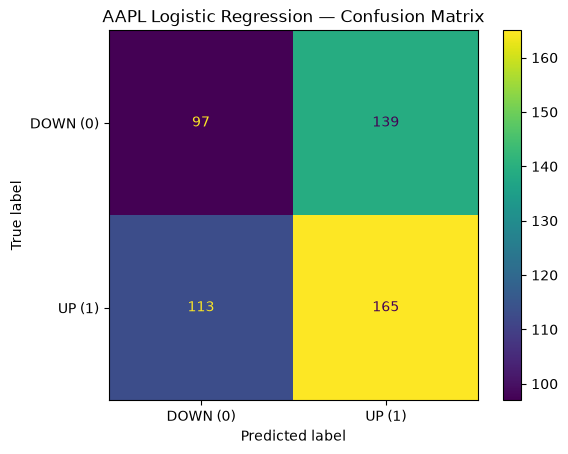

In [23]:
#Confusion matrix for the logistic regression model
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    labels=[0, 1],
    display_labels=["DOWN (0)", "UP (1)"])

plt.title("AAPL Logistic Regression — Confusion Matrix")
plt.show()

In [24]:
#Classification report for the logistic regression model
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        logistic_predictions,
        labels=[0, 1],
        target_names=["DOWN (0)", "UP (1)"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    DOWN (0)       0.46      0.41      0.43       236
      UP (1)       0.54      0.59      0.57       278

    accuracy                           0.51       514
   macro avg       0.50      0.50      0.50       514
weighted avg       0.51      0.51      0.51       514



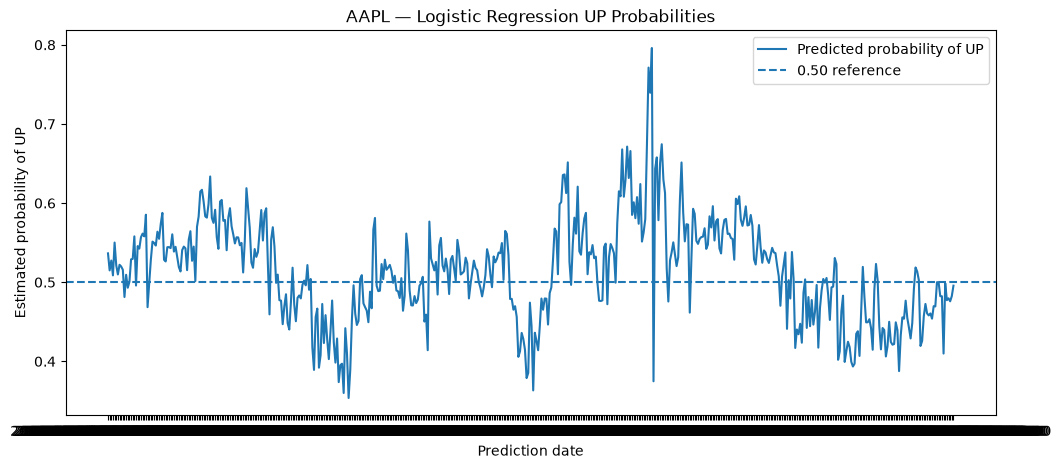

In [25]:
#Plotting the predicted probabilities of UP over time
plt.figure(figsize=(12, 5))

plt.plot(
    test.index,
    probability_up,
    label="Predicted probability of UP")

plt.axhline(
    0.5,
    linestyle="--",
    label="0.50 reference")

plt.title("AAPL — Logistic Regression UP Probabilities")
plt.xlabel("Prediction date")
plt.ylabel("Estimated probability of UP")
plt.legend()
plt.show()

In [27]:
#Analyzing the coefficients of the logistic regression model to understand feature importance
coefficients = classifier.coef_[0]

coefficient_table = pd.DataFrame({
    "Feature": feature_columns,
    "Coefficient": coefficients})

coefficient_table["Absolute Coefficient"] = (coefficient_table["Coefficient"].abs())

coefficient_table = coefficient_table.sort_values("Absolute Coefficient",ascending=False)

coefficient_table

,Feature,Coefficient,Absolute Coefficient
16,BB_percent_b,0.298025,0.298025
0,daily_return,-0.194204,0.194204
12,RSI_14,-0.188130,0.188130
6,SMA_200,0.187494,0.187494
9,price_to_SMA20,0.148086,0.148086
1,return_lag_1,-0.088614,0.088614
13,MACD,-0.080915,0.080915
15,MACD_hist,-0.075917,0.075917
14,MACD_signal,-0.061263,0.061263
4,SMA_20,-0.058589,0.058589
